In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

PROJECT_DIR = r"C:\Users\HomePC\LPG_Optimization_Project"
DATA_CSV    = os.path.join(PROJECT_DIR, "data", "LPG_v2_Data.csv")
MODEL_DIR   = os.path.join(PROJECT_DIR, "models", "v2")
os.makedirs(MODEL_DIR, exist_ok=True)

RUN_PYTORCH          = True   
RUN_DWSIM_VALIDATION = True    
DWSIM_PATH = r"C:\Users\HomePC\Downloads\DWSIM"
SIM_PATH   = r"C:\Users\HomePC\Downloads\LPG_Recovery_v2.dwxmz"

N_TRAIN_GP = 1000     # training points for the final Gaussian process
MARGIN_BAR = 1.5      
SEED = 42

# Energy weighting assumptions
ENERGY = dict(
    T_AMB_C=35.0,          # Lagos design ambient
    T_COND_REF_C=50.0,     # refrigerant condensing temperature (air-cooled condenser)
    APPROACH_C=5.0,        # refrigerant evaporates 5 C below the process temperature
    CARNOT_FRACTION=0.5,   # real refrigeration achieves about half the Carnot COP
    FAN_FRACTION=0.02,     # air-cooler fan power as a fraction of duty
    ETA_POWER=0.33,        # gas-turbine generator
    ETA_HEATER=0.85,       # fired heater
    CO2_KG_PER_KWH_FUEL=0.20,
)

In [2]:
df = pd.read_csv(DATA_CSV)
INPUTS = ["Chiller_Outlet_Temperature_C", "Compressor_Outlet_Pressure_bar",
          "Feed_Mass_Flow_kgh", "Feed_Temperature_C"]
DUTIES = ["Compressor_Power_kW", "Air_Cooler_Duty_kW", "Chiller_Duty_kW",
          "Deethanizer_Condenser_kW", "Deethanizer_Reboiler_kW",
          "Debutanizer_Condenser_kW", "Debutanizer_Reboiler_kW"]
TARGETS = DUTIES + ["LPG_kgh", "Deethanizer_Condenser_T_C", "Compressor_Discharge_T_C"]

df["Failed"] = df["Solve_Status"] != "Success"
ok = df[~df["Failed"]].copy()
print(f"{len(df)} points, {len(ok)} converged, {df['Failed'].sum()} failed")
print(f"Rigorous DWSIM solve time: median {df['Solve_Time_ms'].median():.1f} ms")
DWSIM_MS = df["Solve_Time_ms"].median()

3000 points, 2764 converged, 236 failed
Rigorous DWSIM solve time: median 96.7 ms


In [3]:
E = ENERGY
def cop(t_process_c):
    """Refrigeration COP for cooling a process stream to t_process_c."""
    te = np.asarray(t_process_c) - E["APPROACH_C"] + 273.15
    tc = E["T_COND_REF_C"] + 273.15
    return E["CARNOT_FRACTION"] * te / (tc - te)

def weigh(d, chiller_t):
    """Return electricity (kW), heat (kW) and fuel (kW) from a table of duties."""
    elec = (d["Compressor_Power_kW"]
            + d["Chiller_Duty_kW"] / cop(chiller_t)
            + d["Deethanizer_Condenser_kW"] / cop(d["Deethanizer_Condenser_T_C"])
            + E["FAN_FRACTION"] * (d["Air_Cooler_Duty_kW"] + d["Debutanizer_Condenser_kW"]))
    heat = d["Deethanizer_Reboiler_kW"] + d["Debutanizer_Reboiler_kW"]
    fuel = elec / E["ETA_POWER"] + heat / E["ETA_HEATER"]
    return elec, heat, fuel

ok["Elec_kW"], ok["Heat_kW"], ok["Fuel_kW"] = weigh(ok, ok["Chiller_Outlet_Temperature_C"])
print(f"COP: chiller at 15 C = {cop(15):.2f}, at 25 C = {cop(25):.2f}; deethanizer condenser at -43.7 C = {cop(-43.7):.2f}")

m = ok.median(numeric_only=True)
share = {
    "Compressor": m.Compressor_Power_kW / E["ETA_POWER"],
    "Chiller": m.Chiller_Duty_kW / cop(m.Chiller_Outlet_Temperature_C) / E["ETA_POWER"],
    "Deethanizer refrigeration": m.Deethanizer_Condenser_kW / cop(m.Deethanizer_Condenser_T_C) / E["ETA_POWER"],
    "Air-cooler fans": E["FAN_FRACTION"] * (m.Air_Cooler_Duty_kW + m.Debutanizer_Condenser_kW) / E["ETA_POWER"],
    "Reboiler heat": (m.Deethanizer_Reboiler_kW + m.Debutanizer_Reboiler_kW) / E["ETA_HEATER"],
}
total = sum(share.values())
print("\nWhere the fuel goes (median operating point):")
for k, v in share.items():
    print(f"  {k:28s} {v/total:6.1%}")

COP: chiller at 15 C = 3.54, at 25 C = 4.89; deethanizer condenser at -43.7 C = 1.14

Where the fuel goes (median operating point):
  Compressor                    75.1%
  Chiller                        6.5%
  Deethanizer refrigeration      2.8%
  Air-cooler fans                2.0%
  Reboiler heat                 13.7%


5-fold cross-validation, threshold P(fail) >= 0.5
  Random forest (4 inputs)   caught 221/236  false alarms 5/2764
  Cubic logistic (T, P)      caught 236/236  false alarms 1/2764

Minimum feasible pressure by chiller temperature:
    30 C -> no limit inside 15-35 bar
    34 C -> 15.22 bar
    36 C -> 16.52 bar
    38 C -> 17.95 bar
    40 C -> 19.48 bar
    42 C -> 21.10 bar
    44 C -> 22.85 bar
    45 C -> 23.73 bar


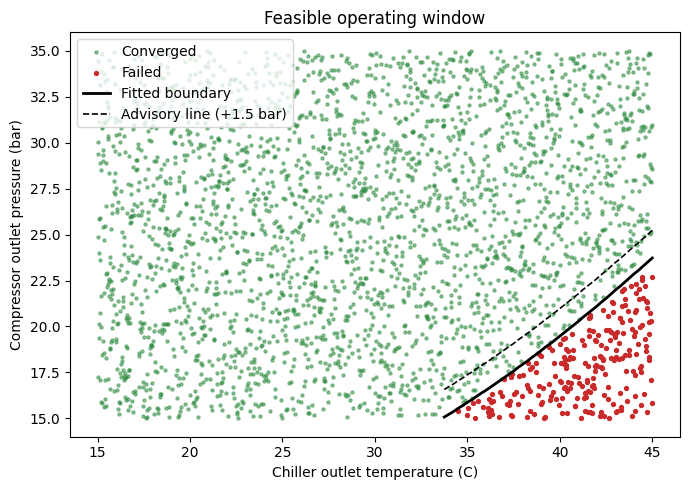

In [4]:
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

Xf, yf = df[INPUTS].values, df["Failed"].values.astype(int)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
candidates = {
    "Random forest (4 inputs)": (RandomForestClassifier(n_estimators=300, random_state=SEED), INPUTS),
    "Cubic logistic (T, P)": (make_pipeline(StandardScaler(), PolynomialFeatures(3),
                                            LogisticRegression(C=100, max_iter=10000)), INPUTS[:2]),
}
print("5-fold cross-validation, threshold P(fail) >= 0.5")
for name, (model, cols) in candidates.items():
    p = cross_val_predict(model, df[cols].values, yf, cv=cv, method="predict_proba")[:, 1]
    caught = ((p >= 0.5) & (yf == 1)).sum(); false = ((p >= 0.5) & (yf == 0)).sum()
    print(f"  {name:26s} caught {caught}/{yf.sum()}  false alarms {false}/{(yf == 0).sum()}")

feas = candidates["Cubic logistic (T, P)"][0].fit(df[INPUTS[:2]].values, yf)
_P = np.linspace(15, 35, 801)
def p_min(t_c):
    """Lowest feasible compressor pressure (bar) at chiller temperature t_c.
    NaN means the plant is feasible down to 15 bar, i.e. there is no boundary at this temperature."""
    pf = feas.predict_proba(np.c_[np.full_like(_P, t_c), _P])[:, 1]
    return float(_P[np.argmax(pf < 0.5)]) if pf[0] >= 0.5 else np.nan
def margin_bar(t_c, p_bar):
    """Distance above the feasibility boundary in bar (negative = inside the failure region, inf = no boundary)."""
    pm = p_min(t_c)
    return np.inf if np.isnan(pm) else p_bar - pm

print("\nMinimum feasible pressure by chiller temperature:")
for t in [30, 34, 36, 38, 40, 42, 44, 45]:
    pm = p_min(t)
    print(f"  {t:4.0f} C -> " + ("no limit inside 15-35 bar" if np.isnan(pm) else f"{pm:5.2f} bar"))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df.loc[~df.Failed, INPUTS[0]], df.loc[~df.Failed, INPUTS[1]], s=5, c="#2b8a3e", alpha=0.5, label="Converged")
ax.scatter(df.loc[df.Failed, INPUTS[0]], df.loc[df.Failed, INPUTS[1]], s=8, c="#c92a2a", label="Failed")
tt = np.linspace(15, 45, 121); bnd = np.array([p_min(t) for t in tt])
ax.plot(tt, bnd, "k-", lw=2, label="Fitted boundary")
ax.plot(tt, np.minimum(bnd + MARGIN_BAR, 35), "k--", lw=1.2, label=f"Advisory line (+{MARGIN_BAR} bar)")   # NaN gaps = no boundary
ax.set_xlabel("Chiller outlet temperature (C)"); ax.set_ylabel("Compressor outlet pressure (bar)")
ax.set_title("Feasible operating window"); ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C
from sklearn.metrics import r2_score

X, Y = ok[INPUTS].values, ok[TARGETS].values
Xtr, Xtmp, Ytr, Ytmp = train_test_split(X, Y, test_size=0.30, random_state=SEED)
Xva, Xte, Yva, Yte = train_test_split(Xtmp, Ytmp, test_size=0.50, random_state=SEED)
near_edge = np.array([margin_bar(t, p) for t, p in Xte[:, :2]]) < 3.0
iLPG = TARGETS.index("LPG_kgh")

class GPSurrogate:
    """Gaussian process with input/output scaling; predict() can also return the standard deviation."""
    def __init__(self, seed=SEED):
        self.seed = seed
    def fit(self, X, Y):
        self.sx, self.sy = StandardScaler().fit(X), StandardScaler().fit(Y)
        kernel = C(1.0) * RBF(np.ones(X.shape[1])) + WhiteKernel(1e-6)
        self.gp = GaussianProcessRegressor(kernel, random_state=self.seed).fit(self.sx.transform(X), self.sy.transform(Y))
        return self
    def predict(self, X, return_std=False, chunk=500):
        """Predict in chunks of 500 points: much faster than one huge kernel matrix."""
        Xs = self.sx.transform(X)
        parts = [self.gp.predict(Xs[i:i + chunk], return_std=return_std) for i in range(0, len(Xs), chunk)]
        if return_std:
            mu = np.vstack([p[0] for p in parts]); sd = np.vstack([p[1] for p in parts])
            return self.sy.inverse_transform(mu), sd * self.sy.scale_
        return self.sy.inverse_transform(np.vstack(parts))

def evaluate(name, pred, fit_s, us_per_pt):
    r2 = [r2_score(Yte[:, i], pred[:, i]) for i in range(len(TARGETS))]
    e_true, e_pred = Yte[:, :len(DUTIES)].sum(1), pred[:, :len(DUTIES)].sum(1)
    e_err = np.abs(e_pred - e_true) / e_true * 100
    l_err = np.abs(pred[:, iLPG] - Yte[:, iLPG])
    return {"Model": name, "Worst R2": round(min(r2), 6),
            "LPG RMSE (kg/h)": round(float(np.sqrt(np.mean((pred[:, iLPG] - Yte[:, iLPG])**2))), 3),
            "Energy err mean (%)": round(e_err.mean(), 3), "Energy err max (%)": round(e_err.max(), 2),
            "Near-edge LPG err max (kg/h)": round(l_err[near_edge].max(), 2),
            "Fit (s)": round(fit_s, 1), "Predict (us/pt)": round(us_per_pt, 1)}

def timed(model_fit, model_predict):
    t = time.perf_counter(); model_fit(); fit_s = time.perf_counter() - t
    t = time.perf_counter(); pred = model_predict(); us = (time.perf_counter() - t) / len(Xte) * 1e6
    return pred, fit_s, us

results = []
for d in [2, 3, 6]:
    m = make_pipeline(StandardScaler(), PolynomialFeatures(d), LinearRegression())
    results.append(evaluate(f"Polynomial deg {d}", *timed(lambda: m.fit(Xtr, Ytr), lambda: m.predict(Xte))))
gp_cmp = GPSurrogate()
results.append(evaluate("Gaussian process", *timed(lambda: gp_cmp.fit(Xtr, Ytr), lambda: gp_cmp.predict(Xte))))

In [6]:
if RUN_PYTORCH:
    import torch, torch.nn as nn
    from torch.utils.data import TensorDataset, DataLoader
    torch.manual_seed(SEED)

    class SurrogateNet(nn.Module):
        def __init__(self, n_in, n_out):
            super().__init__()
            self.net = nn.Sequential(nn.Linear(n_in, 64), nn.SiLU(), nn.Linear(64, 128), nn.SiLU(),
                                     nn.Linear(128, 64), nn.SiLU(), nn.Linear(64, n_out))
        def forward(self, x):
            return self.net(x)

    def train_nn(Xtr, Ytr, Xva, Yva, epochs=800):
        sx, sy = StandardScaler().fit(Xtr), StandardScaler().fit(Ytr)
        f32 = lambda a: torch.tensor(a, dtype=torch.float32)
        loader = DataLoader(TensorDataset(f32(sx.transform(Xtr)), f32(sy.transform(Ytr))), batch_size=64, shuffle=True)
        xv, yv = f32(sx.transform(Xva)), f32(sy.transform(Yva))
        net = SurrogateNet(Xtr.shape[1], Ytr.shape[1])
        opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-5)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=20)
        best, best_state = float("inf"), None
        for ep in range(epochs):
            net.train()
            for xb, yb in loader:
                opt.zero_grad(); loss = nn.functional.mse_loss(net(xb), yb); loss.backward(); opt.step()
            net.eval()
            with torch.no_grad():
                v = nn.functional.mse_loss(net(xv), yv).item()
            sched.step(v)
            if v < best:
                best, best_state = v, {k: t.clone() for k, t in net.state_dict().items()}
        net.load_state_dict(best_state); net.eval()
        def predict(Xq):
            with torch.no_grad():
                return sy.inverse_transform(net(f32(sx.transform(Xq))).numpy())
        return net, predict

    holder = {}
    pred, fit_s, us = timed(lambda: holder.update(nn_=train_nn(Xtr, Ytr, Xva, Yva)), lambda: holder["nn_"][1](Xte))
    results.append(evaluate("Neural net (PyTorch)", pred, fit_s, us))

pd.set_option("display.width", 250)
comparison = pd.DataFrame(results)
comparison

,Model,Worst R2,LPG RMSE (kg/h),Energy err mean (%),Energy err max (%),Near-edge LPG err max (kg/h),Fit (s),Predict (us/pt)
0,Polynomial deg 2,0.998810,1.075,0.561,4.32,4.62,0.0,4.1
1,Polynomial deg 3,0.999721,0.214,0.093,0.95,0.74,0.0,2.3
2,Polynomial deg 6,0.999951,0.008,0.007,0.10,0.04,0.1,8.8
3,Gaussian process,0.999991,0.011,0.009,0.13,0.04,105.2,466.1
4,Neural net (PyTorch),0.999943,0.056,0.035,0.59,0.26,141.3,13.5


In [7]:
def energy_err(Ytrue, pred):
    et, ep = Ytrue[:, :len(DUTIES)].sum(1), pred[:, :len(DUTIES)].sum(1)
    e = np.abs(ep - et) / et * 100
    return f"mean {e.mean():6.3f}%  max {e.max():6.2f}%"

def fitters():
    yield "Polynomial deg 3", lambda Xa, Ya: make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()).fit(Xa, Ya).predict
    yield "Polynomial deg 6", lambda Xa, Ya: make_pipeline(StandardScaler(), PolynomialFeatures(6), LinearRegression()).fit(Xa, Ya).predict
    yield "Gaussian process", lambda Xa, Ya: GPSurrogate().fit(Xa, Ya).predict
    if RUN_PYTORCH:
        yield "Neural net (PyTorch)", lambda Xa, Ya: train_nn(Xa, Ya, Xva, Yva, epochs=400)[1]

print("A. Fewer simulator runs (energy error on the same test set)")
rng = np.random.default_rng(0)
for n in [100, 250, 500]:
    idx = rng.choice(len(Xtr), n, replace=False)
    for name, fit in fitters():
        print(f"  n={n:4d}  {name:22s} {energy_err(Yte, fit(Xtr[idx], Ytr[idx])(Xte))}")

print("\nB. Outside the training range (train on one side, test on the other)")
for label, mask in [("chiller T > 40 C", X[:, 0] > 40), ("feed flow > 1120 kg/h", X[:, 2] > 1120),
                    ("pressure > 32 bar", X[:, 1] > 32)]:
    print(f"  {label} (test n={mask.sum()})")
    for name, fit in fitters():
        print(f"     {name:22s} {energy_err(Y[mask], fit(X[~mask], Y[~mask])(X[mask]))}")

A. Fewer simulator runs (energy error on the same test set)
  n= 100  Polynomial deg 3       mean  0.116%  max   0.92%
  n= 100  Polynomial deg 6       mean 10.412%  max 186.22%
  n= 100  Gaussian process       mean  0.037%  max   0.39%
  n= 100  Neural net (PyTorch)   mean  0.275%  max   3.02%
  n= 250  Polynomial deg 3       mean  0.107%  max   1.35%
  n= 250  Polynomial deg 6       mean  0.027%  max   0.50%
  n= 250  Gaussian process       mean  0.023%  max   0.35%
  n= 250  Neural net (PyTorch)   mean  0.198%  max   2.73%
  n= 500  Polynomial deg 3       mean  0.093%  max   0.85%
  n= 500  Polynomial deg 6       mean  0.009%  max   0.18%
  n= 500  Gaussian process       mean  0.015%  max   0.17%
  n= 500  Neural net (PyTorch)   mean  0.106%  max   1.41%

B. Outside the training range (train on one side, test on the other)
  chiller T > 40 C (test n=328)
     Polynomial deg 3       mean  0.173%  max   1.02%
     Polynomial deg 6       mean  0.086%  max   0.44%
     Gaussian process 

In [8]:
idx = np.random.default_rng(SEED).choice(len(Xtr), min(N_TRAIN_GP, len(Xtr)), replace=False)
gp = GPSurrogate().fit(Xtr[idx], Ytr[idx])
pred_te, sd_te = gp.predict(Xte, return_std=True)
final = evaluate(f"Gaussian process ({len(idx)} pts)", pred_te, 0, 0)
print({k: v for k, v in final.items() if k not in ("Fit (s)", "Predict (us/pt)")})

# Speed on a 40,000-point grid (best of 3 runs, after a warm-up call)
Q = np.random.default_rng(1).uniform([15, 15, 800, 25], [45, 35, 1200, 45], (40000, 4))
def best_time(fn, reps=3):
    fn()  # warm-up
    times = []
    for _ in range(reps):
        t = time.perf_counter(); fn(); times.append(time.perf_counter() - t)
    return min(times)
us_mean = best_time(lambda: gp.predict(Q)) / len(Q) * 1e6
us_std = best_time(lambda: gp.predict(Q, return_std=True), reps=2) / len(Q) * 1e6
print(f"\nPrediction: {us_mean:.1f} us/pt ({DWSIM_MS*1e3/us_mean:,.0f}x faster than DWSIM's {DWSIM_MS:.1f} ms)")
print(f"With uncertainty: {us_std:.1f} us/pt ({DWSIM_MS*1e3/us_std:,.0f}x faster)")
print(f"40,000-point search: {us_mean*40000/1e6:.2f} s vs about {DWSIM_MS*40000/3.6e6:.1f} h in DWSIM")

inside = X[:, 0] <= 40
gp_chk = GPSurrogate().fit(X[inside][:N_TRAIN_GP], Y[inside][:N_TRAIN_GP])
_, sd_in = gp_chk.predict(X[inside][N_TRAIN_GP:N_TRAIN_GP + 400], return_std=True)
p_out, sd_out = gp_chk.predict(X[~inside], return_std=True)
err_out = np.abs(p_out[:, iLPG] - Y[~inside][:, iLPG])
print(f"\nLPG uncertainty: inside training range {sd_in[:, iLPG].mean():.3f} kg/h, "
      f"outside {sd_out[:, iLPG].mean():.3f} kg/h (x{sd_out[:, iLPG].mean() / sd_in[:, iLPG].mean():.1f})")
print(f"Outside the range, correlation between predicted uncertainty and actual error = "
      f"{np.corrcoef(err_out, sd_out[:, iLPG])[0, 1]:.2f}")

{'Model': 'Gaussian process (1000 pts)', 'Worst R2': 0.999982, 'LPG RMSE (kg/h)': 0.015, 'Energy err mean (%)': np.float64(0.012), 'Energy err max (%)': np.float64(0.13), 'Near-edge LPG err max (kg/h)': np.float64(0.05)}

Prediction: 119.3 us/pt (810x faster than DWSIM's 96.7 ms)
With uncertainty: 119.5 us/pt (809x faster)
40,000-point search: 4.77 s vs about 1.1 h in DWSIM

LPG uncertainty: inside training range 0.104 kg/h, outside 0.140 kg/h (x1.3)
Outside the range, correlation between predicted uncertainty and actual error = 0.34


In [9]:
FEED_KGH, FEED_T = 1000.0, 35.0
TT = np.round(np.linspace(15, 45, 121), 3)
PP = np.round(np.linspace(15, 35, 161), 3)
PMIN = {t: p_min(t) for t in TT}

def evaluate_grid(feed_kgh=FEED_KGH, feed_t=FEED_T):
    Tg, Pg = np.meshgrid(TT, PP)
    Q = np.c_[Tg.ravel(), Pg.ravel(), np.full(Tg.size, feed_kgh), np.full(Tg.size, feed_t)]
    pr = pd.DataFrame(gp.predict(Q), columns=TARGETS)
    elec, heat, fuel = weigh(pr, Q[:, 0])
    g = pd.DataFrame({"T": Q[:, 0], "P": Q[:, 1], "LPG": pr["LPG_kgh"], "Elec": elec, "Heat": heat, "Fuel": fuel})
    pm = np.array([PMIN[t] for t in g["T"]])
    g["Safe"] = np.isnan(pm) | (g["P"].values >= pm + MARGIN_BAR)
    g["SEC"] = g["Fuel"] / g["LPG"].clip(lower=1e-3)
    return g

def best(g, target):
    s = g[g.Safe & (g.LPG >= target)]
    return s.loc[s.Fuel.idxmin()] if len(s) else None

def conventional(g, target, p_design=35.0):
    s = g[np.isclose(g.P, p_design) & g.Safe & (g.LPG >= target)]
    return s.loc[s["T"].idxmax()] if len(s) else None

grid = evaluate_grid()
rows = []
for target in [40, 60, 80, 100, 120]:
    b, c = best(grid, target), conventional(grid, target)
    if b is None or c is None:
        continue
    rows.append({"LPG target (kg/h)": target,
                 "Optimum T (C)": b["T"], "Optimum P (bar)": b.P, "Optimum SEC (kWh fuel/kg)": round(b.SEC, 3),
                 "Conventional T (C)": c["T"], "Conventional SEC (kWh fuel/kg)": round(c.SEC, 3),
                 "Fuel saving": f"{1 - b.SEC / c.SEC:.1%}",
                 "kg CO2 per kg LPG (optimum)": round(b.SEC * E["CO2_KG_PER_KWH_FUEL"], 3)})
opt_table = pd.DataFrame(rows)
opt_table

,LPG target (kg/h),Optimum T (C),Optimum P (bar),Optimum SEC (kWh fuel/kg),Conventional T (C),Conventional SEC (kWh fuel/kg),Fuel saving,kg CO2 per kg LPG (optimum)
0,40,16.25,15.000,2.202,38.50,4.209,47.7%,0.440
1,60,15.00,17.750,1.990,32.75,3.002,33.7%,0.398
2,80,15.00,21.375,1.902,27.75,2.441,22.1%,0.380
3,100,15.00,25.625,1.839,22.75,2.094,12.2%,0.368
4,120,15.00,30.875,1.795,18.00,1.879,4.5%,0.359


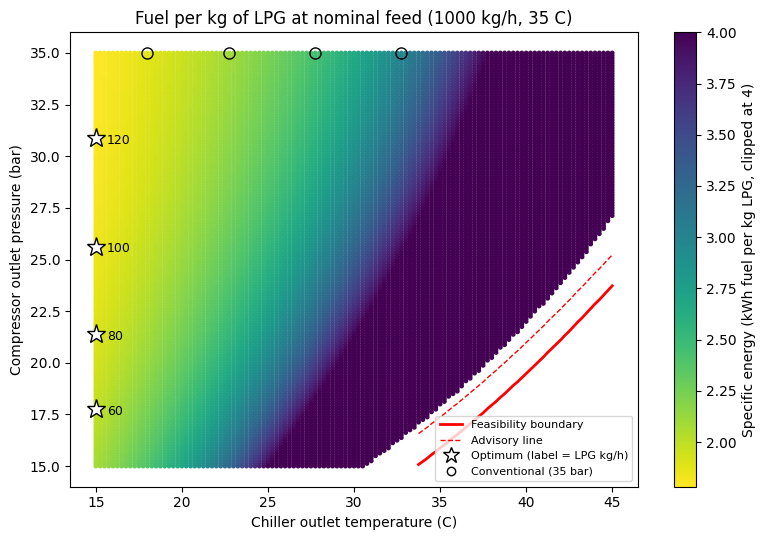

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
v = grid[grid.LPG > 5]
sc = ax.scatter(v["T"], v["P"], c=v["SEC"].clip(upper=4), cmap="viridis_r", s=6)
plt.colorbar(sc, label="Specific energy (kWh fuel per kg LPG, clipped at 4)")
ax.plot(TT, [PMIN[t] for t in TT], "r-", lw=2, label="Feasibility boundary")
ax.plot(TT, np.minimum([PMIN[t] + MARGIN_BAR for t in TT], 35), "r--", lw=1, label="Advisory line")
for target in [60, 80, 100, 120]:
    b, c = best(grid, target), conventional(grid, target)
    ax.plot(b["T"], b.P, "w*", ms=14, mec="k"); ax.plot(c["T"], c.P, "o", mfc="none", mec="k", ms=8)
    ax.annotate(f"{target}", (b["T"], b.P), textcoords="offset points", xytext=(8, -4), fontsize=9)
ax.plot([], [], "w*", mec="k", ms=12, label="Optimum (label = LPG kg/h)")
ax.plot([], [], "o", mfc="none", mec="k", label="Conventional (35 bar)")
ax.set_xlabel("Chiller outlet temperature (C)"); ax.set_ylabel("Compressor outlet pressure (bar)")
ax.set_title("Fuel per kg of LPG at nominal feed (1000 kg/h, 35 C)"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

In [11]:
if RUN_DWSIM_VALIDATION:
    import sys
    from pythonnet import load
    load("coreclr")
    import clr
    os.chdir(DWSIM_PATH)
    if DWSIM_PATH not in sys.path:
        sys.path.append(DWSIM_PATH)
    for ref in ["CapeOpen", "DWSIM.Automation", "DWSIM.Interfaces", "DWSIM.GlobalSettings",
                "DWSIM.SharedClasses", "DWSIM.Thermodynamics"]:
        clr.AddReference(ref)
    from DWSIM.Automation import Automation3
    interf = Automation3(); sim = interf.LoadFlowsheet(SIM_PATH)
    obj = lambda tag: sim.GetFlowsheetSimulationObject(tag).GetAsObject()
    feed, comp, chil, s1, s2 = obj("Raw_Associated_Gas"), obj("C-1"), obj("CL-1"), obj("SCOL-1"), obj("SCOL-2")
    estreams = {"Compressor_Power_kW": "E1", "Air_Cooler_Duty_kW": "E_AC1", "Chiller_Duty_kW": "E2",
                "Deethanizer_Condenser_kW": "Q_Condenser", "Deethanizer_Reboiler_kW": "Q_Reboiler",
                "Debutanizer_Condenser_kW": "E5", "Debutanizer_Reboiler_kW": "E6"}
    estreams = {k: obj(v) for k, v in estreams.items()}
    s_lpg, s_sales = obj("Pure_LPG"), obj("Sales_Gas_C1_C2")

    def dwsim_run(t_c, p_bar, feed_kgh=FEED_KGH, feed_t=FEED_T):
        chil.OutletTemperature = float(t_c + 273.15); comp.POut = float(p_bar * 1e5)
        feed.SetMassFlow(float(feed_kgh / 3600)); feed.SetTemperature(float(feed_t + 273.15))
        s1.m_refluxratio = 20.0; s2.m_refluxratio = 20.0
        interf.CalculateFlowsheet2(sim)                                  # pass 1: minimum reflux
        s1.m_refluxratio = 1.3 * float(s1.m_Rmin); s2.m_refluxratio = 1.3 * float(s2.m_Rmin)
        errs = interf.CalculateFlowsheet2(sim)                           # pass 2: design reflux
        if (errs is not None and errs.Count > 0) or str(s1.ErrorMessage or "").strip() or str(s2.ErrorMessage or "").strip():
            return None
        r = {k: abs(float(es.EnergyFlow)) for k, es in estreams.items()}
        r["LPG_kgh"] = float(s_lpg.GetMassFlow()) * 3600
        r["Deethanizer_Condenser_T_C"] = float(s_sales.GetTemperature()) - 273.15
        elec, heat, fuel = weigh(pd.Series(r), t_c)
        r["Fuel_kW"] = fuel
        return r

    rows = []
    for target in [60, 80, 100, 120]:
        for label, pt in [("Optimum", best(grid, target)), ("Conventional", conventional(grid, target))]:
            r = dwsim_run(pt["T"], pt.P)
            if r is None:
                rows.append({"Target": target, "Case": label, "T": pt["T"], "P": pt.P, "Note": "DWSIM failed"}); continue
            rows.append({"Target": target, "Case": label, "T": pt["T"], "P": pt.P,
                         "Surrogate LPG": round(pt.LPG, 2), "DWSIM LPG": round(r["LPG_kgh"], 2),
                         "LPG err (%)": round(abs(pt.LPG - r["LPG_kgh"]) / r["LPG_kgh"] * 100, 3),
                         "Surrogate fuel": round(pt.Fuel, 2), "DWSIM fuel": round(r["Fuel_kW"], 2),
                         "Fuel err (%)": round(abs(pt.Fuel - r["Fuel_kW"]) / r["Fuel_kW"] * 100, 3),
                         "DWSIM SEC": round(r["Fuel_kW"] / r["LPG_kgh"], 3)})
    val = pd.DataFrame(rows)
    # Savings confirmed by DWSIM
    sec = val.pivot(index="Target", columns="Case", values="DWSIM SEC")
    sec["DWSIM-confirmed saving"] = (1 - sec["Optimum"] / sec["Conventional"]).map("{:.1%}".format)
    display(val); display(sec)

,Target,Case,T,P,Surrogate LPG,DWSIM LPG,LPG err (%),Surrogate fuel,DWSIM fuel,Fuel err (%),DWSIM SEC
0,60,Optimum,15.00,17.750,60.60,60.59,0.021,120.60,120.57,0.021,1.990
1,60,Conventional,32.75,35.000,60.94,60.95,0.017,182.94,182.96,0.008,3.002
2,80,Optimum,15.00,21.375,80.30,80.26,0.051,152.73,152.70,0.017,1.903
3,80,Conventional,27.75,35.000,80.51,80.52,0.007,196.49,196.50,0.005,2.441
4,100,Optimum,15.00,25.625,100.15,100.15,0.002,184.15,184.15,0.000,1.839
5,100,Conventional,22.75,35.000,100.95,100.95,0.003,211.40,211.40,0.001,2.094
6,120,Optimum,15.00,30.875,120.18,120.21,0.025,215.69,215.71,0.010,1.794
7,120,Conventional,18.00,35.000,120.65,120.64,0.010,226.75,226.74,0.004,1.880


Case,Conventional,Optimum,DWSIM-confirmed saving
Target,,,
60,3.002,1.990,33.7%
80,2.441,1.903,22.0%
100,2.094,1.839,12.2%
120,1.880,1.794,4.6%


In [12]:
import joblib
# Save plain scikit-learn objects so the dashboard can load them without this notebook's classes
joblib.dump({"x_scaler": gp.sx, "y_scaler": gp.sy, "gp": gp.gp, "inputs": INPUTS, "targets": TARGETS},
            os.path.join(MODEL_DIR, "gp_surrogate.pkl"))
joblib.dump(feas, os.path.join(MODEL_DIR, "feasibility_boundary.pkl"))
with open(os.path.join(MODEL_DIR, "config.json"), "w") as f:
    json.dump({"inputs": INPUTS, "targets": TARGETS, "duties": DUTIES, "energy": ENERGY,
               "margin_bar": MARGIN_BAR, "dwsim_median_ms": float(DWSIM_MS),
               "n_train_gp": int(len(idx))}, f, indent=2)
opt_table.to_csv(os.path.join(MODEL_DIR, "optimization_results.csv"), index=False)
print("Saved to", MODEL_DIR, ":", os.listdir(MODEL_DIR))

Saved to C:\Users\HomePC\LPG_Optimization_Project\models\v2 : ['config.json', 'feasibility_boundary.pkl', 'gp_surrogate.pkl', 'optimization_results.csv']
